# Create regression input dataset for GDP / capita model

In [1]:
import xarray as xr
import xesmf as xe
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.ops import unary_union
import xagg as xa
import os
import re
import glob
import calendar
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
import cmocean

import warnings
from funcs_support import get_params,get_filepaths,utility_save,utility_print
from funcs_aux import _remove_chunk_encoding

from funcs_plot import plot_map,vals_to_color_triangle
dir_list = get_params()
from fsspec.implementations import local
fs = local.LocalFileSystem()

In [2]:
from distributed import Client

# Start dask client
client = Client()
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /node/crhtc106.hpc.ucar.edu/32600/proxy/8787/status,
Dashboard: /node/crhtc106.hpc.ucar.edu/32600/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 72.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45227,Workers: 0
Dashboard: /node/crhtc106.hpc.ucar.edu/32600/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34407,Total threads: 3
Dashboard: /node/crhtc106.hpc.ucar.edu/32600/proxy/33775/status,Memory: 12.00 GiB
Nanny: tcp://127.0.0.1:39307,


2026-10-12 08:25:36,209 - distributed.scheduler - ERROR - Task ('rechunk-merge-d689fb603dc24863586f3ade1ddbc6aa', 0, 1, 1) has 15.18 GiB worth of input dependencies, but worker tcp://127.0.0.1:37127 has memory_limit set to 12.00 GiB.
2026-10-12 08:29:39,096 - distributed.scheduler - ERROR - Task ('rechunk-merge-d689fb603dc24863586f3ade1ddbc6aa', 0, 1, 1) has 15.18 GiB worth of input dependencies, but worker tcp://127.0.0.1:34407 has memory_limit set to 12.00 GiB.
2026-10-12 08:29:59,396 - distributed.scheduler - ERROR - Task ('rechunk-merge-d689fb603dc24863586f3ade1ddbc6aa', 0, 1, 1) has 15.18 GiB worth of input dependencies, but worker tcp://127.0.0.1:34407 has memory_limit set to 12.00 GiB.
2026-10-12 08:33:35,407 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle ae9e17836e2fde17f4e8489a98083e53 initialized by task ('rechunk-merge-rechunk-transfer-8cacfb08d662a55029be4128a78ae19b', 0, 5, 2, 8, 8, 3) executed on worker tcp://127.0.0.1:37739
2026-10-12 08:33:35,445 - distribu

In [3]:
# Load reference dataset
df_dta = pd.read_csv(dir_list['aux']+'GrowthClimateDataset.csv')

years_insamp = np.unique(df_dta.year.values)

df_dta = df_dta.set_index(['countryname','year'])

In [4]:
# Countries that aren't nan'ed out in the original BHM code
# (this is presumably due to data issues, and good to copy: 
# GMFD is coocoo in the ocean, and especially small island 
# locations have major data issues there)
countries_to_keep = df_dta.loc[:,'UDel_temp_popweight'].dropna()
countries_to_keep = np.unique(countries_to_keep.index.get_level_values('countryname'))

In [5]:
# Load shapefile for insample regions
gdf = gpd.read_file(dir_list['aux']+'geo_data/country.shp')

rename_keys = {'Belarus':'Byelarus',
 'Brunei Darussalam':'Brunei',
 'Cabo Verde':'Cape Verde',
 'Channel Islands':['Jersey','Guernsey'],
 'Congo, Dem. Rep.':'Zaire',
 'Congo, Rep.':'Congo',
 "Cote d'Ivoire":'Ivory Coast',
 'Egypt, Arab Rep.':'Egypt',
 'Hong Kong SAR, China':'Hong Kong', #probably missing,
 'Iran, Islamic Rep.':'Iran',
 'Isle of Man':'Man, Isle of',
 'Korea, Rep.':'South Korea',
 'Kosovo':'Kosovo', # still part of Serbia in this sample
 'Kyrgyz Republic':'Kyrgyzstan',
 'Lao PDR':'Laos',
 'Macao SAR, China':'Macau',
 'Macedonia, FYR':'Macedonia',
 'Micronesia, Fed. Sts.':'Federated States of Micronesia',
 'Palau':'Pacific Islands (Palau)',
 'Russian Federation':'Russia',
 'Samoa':'Western Samoa',
 'Slovak Republic':'Slovakia',
 'Syrian Arab Republic':'Syria',
 'Tanzania':'Tanzania, United Republic of',
 'Timor-Leste':'Timor-Leste', # uh, still part of indonesia in this one... 
 'Venezuela, RB':'Venezuela',
 'West Bank and Gaza':['West Bank','Gaza Strip'],
 'Yemen, Rep.':'Yemen'}
# Switch order
rename_keys = {(tuple(v) if type(v) == list else v):k for k,v in rename_keys.items()}

# Combine into single the ones that are multiple locs in the shapefile but not the repl dataset
combine_locs = {k:v for k,v in rename_keys.items() if type(k) == tuple}
for locs,joint_name in combine_locs.items():
    gdf_tmp = gdf.iloc[[c in locs for c in gdf.CNTRY_NAME.values],:]
    cols = [col for col in gdf_tmp.columns if col != 'geometry']
    
    gdf_joint = pd.concat([gdf_tmp.iloc[0].loc[[col for col in cols if gdf_tmp.dtypes[col] == object]],
                          gdf_tmp.loc[:,[col for col in cols if gdf_tmp.dtypes[col] in [float,int]]].sum()])
    gdf_joint = gpd.GeoDataFrame([gdf_joint],index=[gdf_tmp.index[0]],
                     geometry = [gdf_tmp.union_all()],
                                 crs = gdf_tmp.crs)
    gdf_joint.loc[:,'CNTRY_NAME'] = joint_name
    
    gdf = pd.concat([gdf.iloc[[c not in locs for c in gdf.CNTRY_NAME.values],:],
               gdf_joint])
gdf = gdf.sort_index()

# Rename the rest of the locations as needed
for idx in gdf.index:
    if gdf.loc[idx,'CNTRY_NAME'] in rename_keys:
        gdf.loc[idx,'CNTRY_NAME'] = rename_keys[gdf.loc[idx,'CNTRY_NAME']]

In [6]:
# Load population density
#pop = xr.open_dataset(dir_list['aux']+'pop_data/glp00ag30.asc')
#pop = xa.fix_ds(pop)
#pop = pop.isel(band=0)
pop_fn = dir_list['aux']+'pop_data/gpw_v4_population_count_rev11_025deg_rg.nc'
pop = xr.open_dataset(pop_fn)

In [43]:
df = get_filepaths()

pr_sub_list = ['BEST']
pr_sub_mod = 'ERA5-025'

for obs_mod in ['BEST','ERA5-025','MERRA2','JRA-3Q','GMFD','UDel',
                'ERA5-025-1deg','MERRA2-1deg','JRA-3Q-1deg','GMFD-1deg','UDel-1deg',
                ]:
    print(f'\nProcessing {obs_mod}')
    if obs_mod+'_temp_popweight' in df_dta.columns:
        print(f'{obs_mod} already processed, skipped!')
        continue
    df_tmp = df.query(f'model == "{obs_mod}" and (varname == "tas" or varname == "pr") and freq == "day"')
    if len(df_tmp) == 0:
        df_tmp = df.query(f'model == "{obs_mod}" and (varname == "tas" or varname == "pr") and freq == "Amon"')
        if obs_mod in pr_sub_list:
            df_tmp = pd.concat([df_tmp,
                                df.query(f'model == "{pr_sub_mod}" and varname == "pr" and freq == "day"')])
    
    # Load climate data
    dss = {row[1]['varname']:(xr.open_zarr(row[1]['path']) if '.zarr' in row[1]['path']
                              else xr.open_dataset(row[1]['path'])) for row in df_tmp.iterrows()}
    dss = {var:ds.isel(time=[y in years_insamp for y in ds.time.dt.year.values])
           for var,ds in dss.items()}
    
    # Subset to global land
    params_subset = {'lat':slice(-58,89),
                     'lon':slice(-180,180)}
    dss = {var:ds.sel(**params_subset) for var,ds in dss.items()}
    
    # Convert precip data from kg/m^2s to mm/day
    if obs_mod not in ['UDel','UDel-1deg']:
        dss['pr'] = dss['pr']*60*60*24 # from kg/m^2s to mm/day
    
    # Convert t from K to C
    dss['tas'] = dss['tas'] - 273.15

    # Rechunk
    for v in dss:
        if dss[v].sizes['lat']>100:
            chunks = {'time':-1,'lat':50,'lon':50}
        else:
            chunks = {'time':-1}
        dss[v] = dss[v].chunk(chunks)
    
    # Calculate mean temperature and summed precipitation
    dss = {'tas':dss['tas'].resample(time='1YS').mean(),
           'pr':dss['pr'].resample(time='1YS').sum()}
    
    # Convert time dimension to just year
    for var in dss:
        dss[var]['time'] = dss[var]['time'].dt.year
        dss[var] = dss[var].rename({'time':'year'})

    # Compute means/sums
    with warnings.catch_warnings():
        # Large graph size dask warning
        warnings.filterwarnings('ignore')
        dss = {v:ds.compute() for v,ds in dss.items()} 
    
    # (there's no subnational nonlinearity in this model anyways, but for consistency,)
    # Regrid to 0.25 x 0.25 ref grid, if not 1-deg 
    if '1deg' not in obs_mod:
        fine_grid = xr.Dataset(coords = {'lat':(['lat'],np.arange(params_subset['lat'].start+0.125,
    														 params_subset['lat'].stop-0.124,0.25)),
    								'lon':(['lon'],np.arange(params_subset['lon'].start+0.125,
    														 params_subset['lon'].stop-0.124,0.25))})

        if np.all([dss['pr'].sizes[dim] == dss['tas'].sizes[dim]
                   for dim in ['lat','lon']]):
            rgrd = {'tas':xe.Regridder(dss['tas'],fine_grid,'bilinear')}
            rgrd['pr'] = rgrd['tas']
        else:
            rgrd = {v:xe.Regridder(dss[v],fine_grid,'bilinear') for v in dss}

        for v in dss:
            dss[v] = rgrd[v](dss[v])

    # Merge
    dss = xr.merge([ds for var,ds in dss.items()])

    # For some reason lat_bnds still in file
    dss = dss.drop_vars('lat_bnds',errors='ignore')
    
    # Aggregate
    with warnings.catch_warnings():
        # Weights bbox warning - fine, affects uninhabited arctic, and large graph size dask warning
        warnings.filterwarnings('ignore') 
        # Otherwise divide by 0 error in xa.aggregate, should open a github issue
        wm = xa.pixel_overlaps(dss,gdf,weights=pop.pop)
        
        with xa.set_options(impl='numba',silent=True):
            agg = xa.aggregate(dss,wm)
    
    # Put aggregated data into correct format for merging
    agg_out = (agg.to_dataframe()[['CNTRY_NAME','tas','pr']].
     rename({'CNTRY_NAME':'countryname'},axis=1).
     reset_index().set_index(['countryname','year']).
     drop('poly_idx',axis=1))
    agg_out = agg_out.rename({'tas':f'{obs_mod}_temp_popweight',
                              'pr':f'{obs_mod}_precip_popweight'},
                             axis=1)
    
    # Calculate squared precip
    agg_out[f'{obs_mod}_precip_popweight_2'] = agg_out[f'{obs_mod}_precip_popweight']**2
    
    
    # Join into existing dataset
    df_dta = df_dta.join(agg_out,how='outer')


Processing BEST
BEST already processed, skipped!

Processing ERA5-025
ERA5-025 already processed, skipped!

Processing MERRA2
MERRA2 already processed, skipped!

Processing JRA-3Q
JRA-3Q already processed, skipped!

Processing GMFD
GMFD already processed, skipped!

Processing UDel
UDel already processed, skipped!

Processing ERA5-025-1deg
creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
regridding weights to data grid...
calculating overlaps between pixels and output polygons...
success!

Processing MERRA2-1deg
creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
regridding weights to data grid...
calculating overlaps between pixels and output polygons...
success!

Processing JRA-3Q-1deg
creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
regridding weights to data grid...
calculating overlaps between pixels and output polygons...
success!

Processing GMFD

In [44]:
# Drop rows with no observations
df_dta = df_dta.where(~np.isnan(df_dta.Pop)).dropna(how='all')

In [45]:
# Switch climate column name order
df_dta.columns = [
    c if "popweight" not in c else "_".join(c.split("_")[1:] + [c.split("_")[0]])
    for c in df_dta.columns
]

In [46]:
# Identify variable columns using the known pattern
clim_cols = [c for c in df_dta.reset_index().columns 
              if 'popweight' in c] 

# Melt them
df_long = df_dta.reset_index().melt(
    id_vars=[c for c in df_dta.reset_index().columns if c not in clim_cols],
    value_vars=clim_cols,
    var_name='tmp',
    value_name='value'
)

In [47]:
# Split "temp_popweight_UDel" → var, weight, model
df_long[['var','typ','obs_mod']] = df_long['tmp'].str.rsplit('_', n=2, expand=True)
# Get full variable name back
df_long['var_full'] = df_long['var'] + '_' + df_long['typ']

In [49]:
# Pivot back to wide, with clim variables their own thing now
with warnings.catch_warnings():
    # DataFrame is highly fragmented warning from pandas
    warnings.filterwarnings('ignore')
    df_wide = df_long.pivot_table(
        index=['obs_mod'] + [c for c in df_dta.reset_index().columns if c not in clim_cols],
        columns='var_full',
        values='value'
    ).reset_index()

# Get rid of 'var_full' column namer
df_wide.columns.name = None

# Set indices
df_wide = df_wide.set_index(['countryname','year','obs_mod'])

In [50]:
df_out = (df_long.loc[:,['countryname','year','var_full','obs_mod','value']].pivot_table(
    index = ['countryname','year','obs_mod'],
    columns = 'var_full',
    values = 'value').
 join(df_dta.loc[:,[c for c in df_dta.reset_index().columns 
                    if c not in ['countryname','year',*clim_cols]]]))

In [51]:
df_out['nobs_mods'] = df_out.groupby(['countryname','year']).count()['precip_popweight']

In [52]:
# Flag if in original sample
df_out['og_insamp'] = [k in countries_to_keep for k in df_out.index.get_level_values('countryname')]

In [53]:
df_out_025deg = df_out.iloc[['1deg' not in m for m in df_out.index.get_level_values('obs_mod')],:]
df_out_1deg = df_out.iloc[['1deg' in m for m in df_out.index.get_level_values('obs_mod')],:]

In [55]:
# Export 0.25-deg data
df_out_025deg.to_csv(dir_list['proc']+'reg_inputs/gdppc/reginputs_gdppc_025deg.csv')

# Make the model names identical , without the "1deg" attachment
df_out_1deg = df_out_1deg.reset_index()
df_out_1deg['obs_mod'] = [re.sub(r'\-1deg','',mod) for mod in df_out_1deg.obs_mod.values]
df_out_1deg = df_out_1deg.set_index(['countryname','year','obs_mod'])
# Export 1-deg data
df_out_1deg.to_csv(dir_list['proc']+'reg_inputs/gdppc/reginputs_gdppc_1deg.csv')


## Examples of GMFD issues

In [13]:
df_out = pd.read_csv(dir_list['proc']+'reg_inputs/gdppc/reginputs_gdppc_025deg.csv')
df_out = df_out.set_index(['countryname','year'])

In [26]:
df_small = df_out.where(df_out.Pop.groupby('countryname').mean()<1500000).dropna(how='all')

In [81]:
bad_countries = d.where((d<-3).sum('year') > 0,drop=True).countryname

In [86]:
[k for k in bad_countries.values if k in countries_to_keep]

['Cabo Verde', 'Comoros', 'Costa Rica', 'Eritrea', 'Panama', 'Samoa']

Text(0.5, 1.0, 'GMFD, all countries with at least one year < 3 SD from mean')

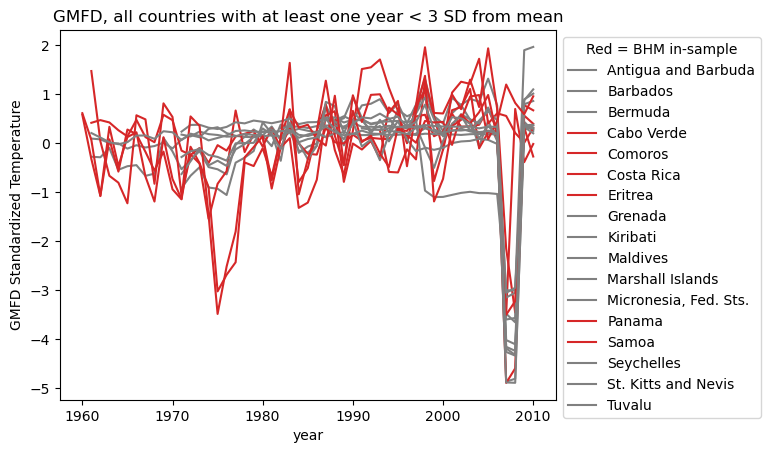

In [98]:
d_bad = d.sel(countryname=bad_countries).sortby('year')
ax = plt.subplot()
for k in d_bad.countryname.values:
    if k in countries_to_keep:
        color='tab:red'
    else:
        color='grey'
    d_bad.sel(countryname=k).plot(label=k,color=color)
ax.legend(bbox_to_anchor=(1,1),title='Red = BHM in-sample')  
ax.set_ylabel('GMFD Standardized Temperature')
ax.set_title('GMFD, all countries with at least one year < 3 SD from mean')

In [109]:
a = xr.open_dataset('/gdex/data/d314000/0.25deg/daily/tmax_0p25_daily_2008-2008.nc',chunks='auto').isel(z=0)
b = xr.open_dataset('/gdex/data/d314000/0.25deg/daily/tmax_0p25_daily_2010-2010.nc',chunks='auto').isel(z=0)

In [112]:
da = a.mean('time').tmax - b.mean('time').tmax

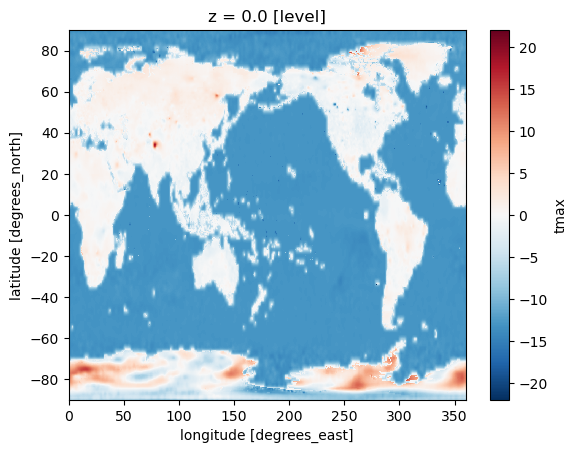

In [116]:
da.plot()

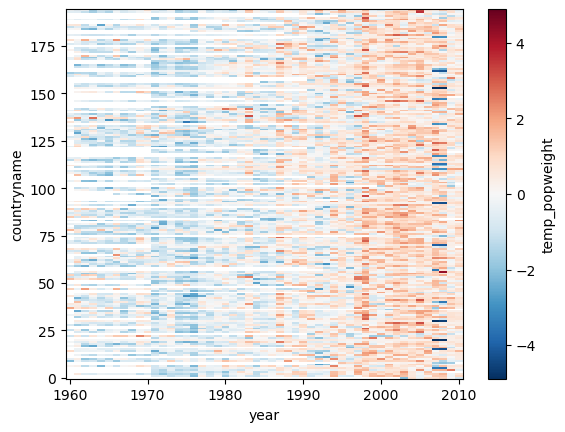

In [64]:
d = df_out.query('obs_mod == "GMFD"').loc[:,'temp_popweight'].to_xarray()
d = (d - d.mean('year'))/d.std('year')
d.reset_index('countryname',drop=True).sortby('year').plot()

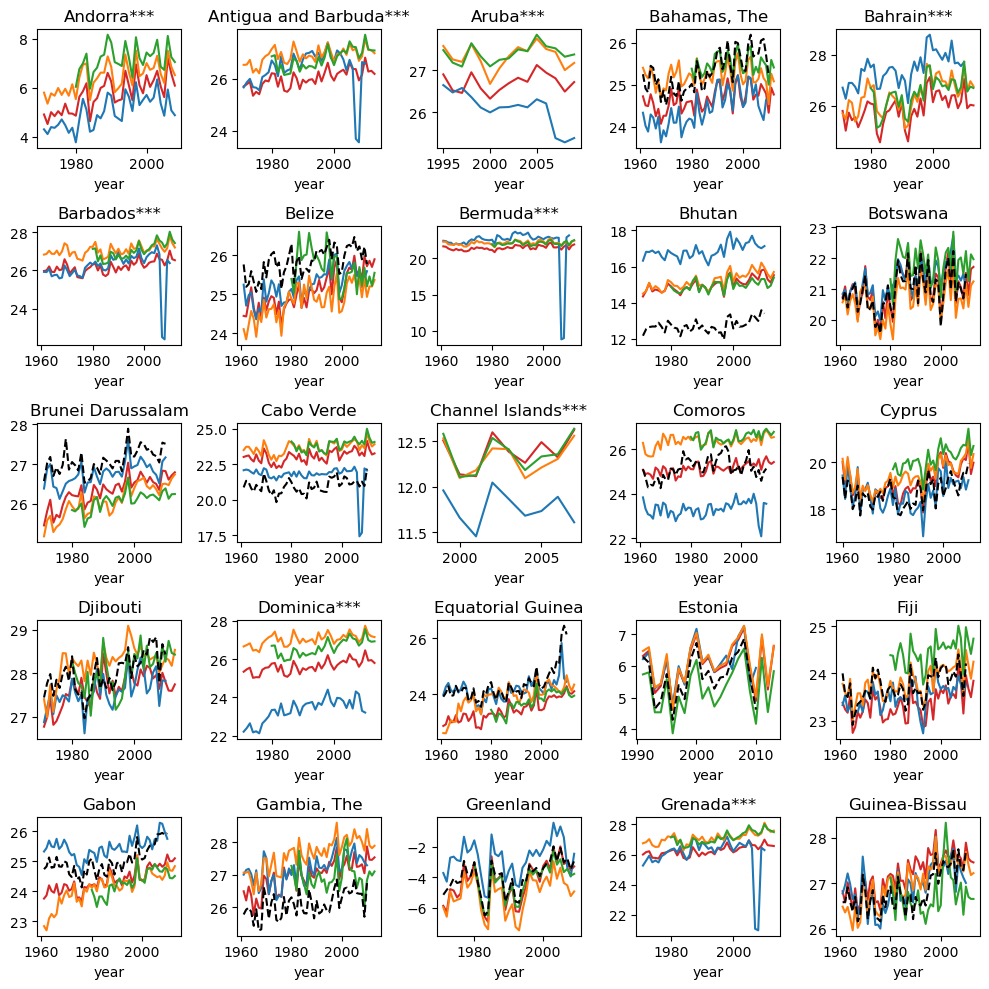

In [34]:
country_list = df_small.reset_index().countryname.unique()

colors = {'ERA5-025':'tab:red',
          'GMFD':'tab:blue',
          'MERRA2':'tab:green',
          'JRA-3Q':'tab:orange'}

fig = plt.figure(figsize=(10,10))

for plt_idx,cntry in enumerate(country_list):
    title = cntry
    if cntry not in countries_to_keep:
        title = title+'***'
    if plt_idx>24:
        continue
    ax = plt.subplot(5,5,plt_idx+1)
    df_tmp = df_small.loc[cntry]
    for pb in ['ERA5-025','GMFD','JRA-3Q','MERRA2']:
        df_tmp.query(f'obs_mod == "{pb}"').loc[:,'temp_popweight'].plot(ax=ax,label=pb,color=colors[pb])
    df_dta.loc[cntry]['UDel_temp_popweight'].plot(ax=ax,label='UDel',color='k',linestyle='--')
    ax.set_title(title)

plt.tight_layout()

In [67]:
df_small.set_index('countryname').loc['Gabon']

,year,obs_mod,precip_popweight,precip_popweight_2,temp_popweight,iso,AgrGDP,Pop,TotGDP,gdpCAP_wdi,...,_y2_isoXtim_193,_y2_isoXtim_194,_y2_isoXtim_195,_y2_isoXtim_196,_y2_isoXtim_197,_y2_isoXtim_198,_y2_isoXtim_199,_y2_isoXtim_200,_y2_isoXtim_201,nobs_mods
countryname,,,,,,,,,,,,,,,,,,,,,
Gabon,1961,ERA5-025,2519.110478,6.345918e+06,23.749121,GAB,NaN,503762.0,1.598000e+09,3171.6448,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8
Gabon,1961,GMFD,2346.392256,5.505557e+06,25.318590,GAB,NaN,503762.0,1.598000e+09,3171.6448,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8
Gabon,1961,JRA-3Q,1970.481017,3.882795e+06,22.828452,GAB,NaN,503762.0,1.598000e+09,3171.6448,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8
Gabon,1961,UDel,2285.710000,5.224470e+06,24.730000,GAB,NaN,503762.0,1.598000e+09,3171.6448,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8
Gabon,1962,ERA5-025,2121.124119,4.499168e+06,23.854820,GAB,NaN,509348.0,1.717000e+09,3370.5330,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Gabon,1992,ERA5-025,2070.636270,4.287535e+06,24.184634,GAB,348100000.0,998823.0,6.936000e+09,6943.6731,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10
Gabon,1992,GMFD,1749.909327,3.062183e+06,25.316323,GAB,348100000.0,998823.0,6.936000e+09,6943.6731,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10
Gabon,1992,JRA-3Q,1615.934239,2.611243e+06,24.080484,GAB,348100000.0,998823.0,6.936000e+09,6943.6731,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10


In [64]:
df_dta.loc['Gabon']

,iso,AgrGDP,Pop,TotGDP,gdpCAP_wdi,gdpCAPppp_wdi,isocode,NonAgrGDP,growthWDI,AgrGDPgrowth,...,_y2_isoXtim_192,_y2_isoXtim_193,_y2_isoXtim_194,_y2_isoXtim_195,_y2_isoXtim_196,_y2_isoXtim_197,_y2_isoXtim_198,_y2_isoXtim_199,_y2_isoXtim_200,_y2_isoXtim_201
year,,,,,,,,,,,,,,,,,,,,,
1961,GAB,NaN,503762.0,1.598000e+09,3171.6448,NaN,GAB,NaN,0.127880,NaN,...,0,0,0,0,0,0,0,0,0,0
1962,GAB,NaN,509348.0,1.717000e+09,3370.5330,NaN,GAB,NaN,0.060821,NaN,...,0,0,0,0,0,0,0,0,0,0
1963,GAB,NaN,515762.0,1.821000e+09,3531.4110,NaN,GAB,NaN,0.046627,NaN,...,0,0,0,0,0,0,0,0,0,0
1964,GAB,NaN,523236.0,1.904000e+09,3639.5067,NaN,GAB,NaN,0.030151,NaN,...,0,0,0,0,0,0,0,0,0,0
1965,GAB,NaN,531901.0,2.063000e+09,3878.5684,NaN,GAB,NaN,0.063618,NaN,...,0,0,0,0,0,0,0,0,0,0
1966,GAB,NaN,541895.0,2.156000e+09,3978.6585,NaN,GAB,NaN,0.025479,NaN,...,0,0,0,0,0,0,0,0,0,0
1967,GAB,NaN,553098.0,2.245000e+09,4058.4824,NaN,GAB,NaN,0.019864,NaN,...,0,0,0,0,0,0,0,0,0,0
1968,GAB,NaN,565080.0,2.301000e+09,4072.0863,NaN,GAB,NaN,0.003346,NaN,...,0,0,0,0,0,0,0,0,0,0
1969,GAB,NaN,577241.0,2.487000e+09,4308.5067,NaN,GAB,NaN,0.056436,NaN,...,0,0,0,0,0,0,0,0,0,0
